# ANÁLISIS EXPLORATORIO DATOS GENERACIÓN COLOMBIA

## 1. Documentación de la base de datos:

https://sig.upme.gov.co/portal/apps/sites/#/geoportal-sectorial-gps/datasets/c96b33304e8a436ab118fea9a4a737d4/explore?location=6.116120%2C-74.644210%2C4.99

Se realizó la extracción de la base de datos de Proyectos de Generación XM desde el Geoportal Sectorial (GPS) de la Unidad de Planeación Minero Energética (UPME) a través de su servicio REST de ArcGIS Server. 

La captura de los datos se efectuó mediante el consumo directo del endpoint vectorial en formato GeoJSON (FeatureServer/24), lo que garantizó la obtención de la totalidad de los registros activos sin interrupciones por límite de registros. Esta capa integra la georreferenciación puntual de la infraestructura de generación bajo el sistema de referencia oficial MAGNA-SIRGAS Origen Nacional (EPSG:9377) —reproyectado localmente a WGS84 (EPSG:4326)— e incluye atributos clave como la capacidad efectiva neta ($\text{MW}$), el tipo de tecnología de generación, el estado operativo del recurso, el agente representante y la ubicación político-administrativa (departamento y municipio).

# Ficha Técnica de Extracción

**Fuente de datos:** Geoportal Sectorial GPS — UPME (Unidad de Planeación Minero Energética)

**Identificador del Dataset:** c96b33304e8a436ab118fea9a4a737d4

**Capa / Servicio:** proyectos_generacion_xm (ID Capa: 24)

**Método de adquisición:** Consulta HTTP GET sobre la API REST de ArcGIS Server (f=geojson)

**Proyección espacial origen / destino:** EPSG:9377 (MAGNA-SIRGAS Origen Nacional) $\rightarrow$ EPSG:4326 (WGS84)

**Variables Principales:** codigo_sic, nombre_recurso, capacidad_efectiva_neta_mw, tipo_generacion, estado_recurso, agente_representante, fecha_operacion, municipio_oficial, departamento_oficial

Consultar documentación completa Campos: https://geo.upme.gov.co/server/rest/services/Capas_EnergiaElectrica/proyectos_generacion_xm/FeatureServer/24


## 2. Introducción

Este análisis exploratorio examina la composición del sistema de generación eléctrica nacional en Colombia a partir de los registros geoespaciales de la UPME. El procesamiento de estos datos permite caracterizar la infraestructura activa según su capacidad instalada ($\text{MW}$), tecnología empleada y estado operativo, ofreciendo una visión integral sobre la configuración del parque generador del país.   

## 3. Carga de Datos

In [92]:
import requests
import geopandas as gpd
import pandas as pd
import urllib3
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

URL_GEOJSON = "https://geo.upme.gov.co/server/rest/services/Capas_EnergiaElectrica/proyectos_generacion_xm/FeatureServer/24/query?outFields=*&where=1%3D1&f=geojson"


response = requests.get(URL_GEOJSON, verify=False)
gdf_proyectos = gpd.read_file(response.text)


print(f"Carga exitosa: {len(gdf_proyectos)} proyectos cargados.")
gdf_proyectos.head()

Carga exitosa: 681 proyectos cargados.


,id,anio_fpo,codigo_sic,nombre_recurso,capacidad_efectiva_neta_mw,factor_conversion,es_menor,tipo_despacho,combustible_defecto,fecha_operacion,agente_representante,estado_recurso,tipo_generacion,clasificacion,fecha,municipio_oficial,cod_mpio,departamento_oficial,geometry
0,1,2007,ABJ1,LA CASCADA ( ABEJORRAL),3.00,0.0000,SI,ND,AGUA,1189987200000,EMPRESA DE GENERACION Y PROMOCION DE ENERGIA D...,OPERACIÓN,HIDRAULICA,NORMAL,1792999640000,ABEJORRAL,05002,ANTIOQUIA,POINT (-75.43849 5.80372)
1,2,2017,2TUT,LUZMA I,19.60,3.6594,SI,ND,AGUA,1507334400000,BTG PACTUAL COMMODITIES COLOMBIA S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,1792999640000,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)
2,3,2017,2TUV,LUZMA II,19.60,3.6351,SI,ND,AGUA,1507334400000,BTG PACTUAL COMMODITIES COLOMBIA S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,1792999640000,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)
3,4,2001,PRC2,PORCE II,405.00,2.1432,NO,DC,AGUA,986688000000,EMPRESAS PUBLICAS DE MEDELLIN E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,1792999640000,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)
4,5,2007,AMF1,AMALFI,0.81,0.0000,SI,ND,AGUA,1186272000000,HZ ENERGY S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,GEN. DISTRIBUIDA,1792999640000,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)


In [93]:
gdf_proyectos.estado_recurso.value_counts()

OPERACIÓN    479
PRUEBAS      140
INACTIVO      62
Name: estado_recurso, dtype: int64

In [94]:
# Observamos una gran cantidad de plantas en procesos de pruebas, vamos a verificarlas rápidamente.

print("El reporte descargado presenta en su totalidad",gdf_proyectos[gdf_proyectos['estado_recurso']=='PRUEBAS'].capacidad_efectiva_neta_mw.sum().round(0),'MW')

# Revisemos a que tipo de tecnologías corresponden.
print("")
print("Al segmentar la cantidad de potencia instalada, pero actualmente en pruebas, tenemos:")
print("")
gdf_proyectos[gdf_proyectos['estado_recurso']=='PRUEBAS'].groupby('tipo_generacion').capacidad_efectiva_neta_mw.sum().round(0)

El reporte descargado presenta en su totalidad 1135.0 MW

Al segmentar la cantidad de potencia instalada, pero actualmente en pruebas, tenemos:



tipo_generacion
EOLICA          41.0
HIDRAULICA      10.0
SOLAR         1071.0
TERMICA         13.0
Name: capacidad_efectiva_neta_mw, dtype: float64

A simple vista la cantidad de generación instalada en la étapa de pruebas es elevada, sin embargo, al comparar con el tamaño del sistema representa alrededor del 5%, lo cual es razonable para este estado de trámite, esto sin embargo no implica que el sistema no esté recibiendo generación de estás plantas, en muchas ocasiones podrían estar generando bloques grandes, sin embargo, la etiqueta de pruebas probablemente cambios sus reglas de juego comerciales y el potencial de acceder a pagos de cargo por confiabilidad.

In [95]:
gdf_proyectos[gdf_proyectos['estado_recurso']=='PRUEBAS'].fecha_operacion

32     1787875200000
41     1692835200000
58     1692748800000
82     1713657600000
93     1760745600000
           ...      
669    1660521600000
670    1651881600000
676    1627603200000
679    1711152000000
680    1572739200000
Name: fecha_operacion, Length: 140, dtype: int64

In [96]:
gdf_proyectos[gdf_proyectos['estado_recurso']=='PRUEBAS'].groupby('clasificacion').capacidad_efectiva_neta_mw.sum().round(0)

clasificacion
AUTOGENERADOR       152.0
GEN. DISTRIBUIDA     35.0
NORMAL              948.0
Name: capacidad_efectiva_neta_mw, dtype: float64

Tras revisar las fechas de entrada en operación, podemos confirmar que algunas plantas registran una fecha de conexión o hito inicial antiguo, pero se encuentran actualmente en un proceso de re-certificación o pruebas de inyección, en cuanto a la segmentación por clasificación: incluye plantas normales, autogeneradores y generación distribuida. Dicho esto para efectos del análisis del Sistema de Generación emplearemos exclusivamente aquellos en operación.

In [97]:
# Dejamos solo las categorías en operación.
gdf_proyectos=gdf_proyectos[gdf_proyectos['estado_recurso']=='OPERACIÓN']

**Nota.** Es fundamental entender que el proceso de análisis solamente contemplara los 479 proyectos designados en el estado Operación, si bien se cuentan 140 instancias en pruebas, se descartarán en el proceso con el fin de evitar sobreestimar el parque de generación confirmado.

## 4. Verificación y limpieza.

In [98]:
# Examinamos la totalidad de columnas disponibles.

gdf_proyectos.columns

Index(['id', 'anio_fpo', 'codigo_sic', 'nombre_recurso',
       'capacidad_efectiva_neta_mw', 'factor_conversion', 'es_menor',
       'tipo_despacho', 'combustible_defecto', 'fecha_operacion',
       'agente_representante', 'estado_recurso', 'tipo_generacion',
       'clasificacion', 'fecha', 'municipio_oficial', 'cod_mpio',
       'departamento_oficial', 'geometry'],
      dtype='object')

In [99]:
# El comando .info() nos permite observar la completitud de los datos y su tipo.

gdf_proyectos.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Int64Index: 479 entries, 0 to 678
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   id                          479 non-null    int64   
 1   anio_fpo                    479 non-null    int64   
 2   codigo_sic                  479 non-null    object  
 3   nombre_recurso              479 non-null    object  
 4   capacidad_efectiva_neta_mw  479 non-null    float64 
 5   factor_conversion           479 non-null    float64 
 6   es_menor                    479 non-null    object  
 7   tipo_despacho               479 non-null    object  
 8   combustible_defecto         479 non-null    object  
 9   fecha_operacion             479 non-null    int64   
 10  agente_representante        479 non-null    object  
 11  estado_recurso              479 non-null    object  
 12  tipo_generacion             479 non-null    object  
 13  clasificacio

In [100]:
gdf_proyectos.describe()

,id,anio_fpo,capacidad_efectiva_neta_mw,factor_conversion,fecha_operacion,fecha
count,479.000000,479.000000,479.000000,479.000000,4.790000e+02,4.790000e+02
mean,320.728601,2012.417537,46.553933,1.544502,1.352529e+12,1.793000e+12
std,197.427264,21.324475,147.314651,3.491244,6.762320e+11,0.000000e+00
min,1.000000,1925.000000,0.000000,0.000000,-1.420070e+12,1.793000e+12
25%,148.500000,2008.500000,0.990000,0.000000,1.220789e+12,1.793000e+12
50%,315.000000,2024.000000,1.670000,0.000000,1.708560e+12,1.793000e+12
75%,494.500000,2026.000000,19.800000,1.000000,1.768046e+12,1.793000e+12
max,679.000000,2026.000000,1250.000000,29.260000,1.792195e+12,1.793000e+12


El conjunto de datos presenta una excelente completitud y valores dentro de los rangos esperados. Para asegurar la consistencia técnica del análisis, se transformaron las marcas de tiempo en milisegundos al tipo fecha correspondiente y se tipificaron las variables de clasificación como categóricas.

In [101]:
date_columns = ['fecha_operacion', 'fecha']  # Convertimos ambos campos tanto el de fecha, como el de fecha de operación.

for col in date_columns:
    if col in gdf_proyectos.columns:
        gdf_proyectos[col] = pd.to_datetime(
            pd.to_numeric(gdf_proyectos[col], errors='coerce'), 
            unit='ms'
        )

In [102]:
cat_cols = ['tipo_generacion', 'estado_recurso', 'combustible_defecto', 'es_menor', 'clasificacion', 'tipo_despacho']
gdf_proyectos[cat_cols] = gdf_proyectos[cat_cols].astype('category')

In [103]:
# Revisamos los cambios ejecutados.
gdf_proyectos.head()

,id,anio_fpo,codigo_sic,nombre_recurso,capacidad_efectiva_neta_mw,factor_conversion,es_menor,tipo_despacho,combustible_defecto,fecha_operacion,agente_representante,estado_recurso,tipo_generacion,clasificacion,fecha,municipio_oficial,cod_mpio,departamento_oficial,geometry
0,1,2007,ABJ1,LA CASCADA ( ABEJORRAL),3.00,0.0000,SI,ND,AGUA,2007-09-17,EMPRESA DE GENERACION Y PROMOCION DE ENERGIA D...,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,ABEJORRAL,05002,ANTIOQUIA,POINT (-75.43849 5.80372)
1,2,2017,2TUT,LUZMA I,19.60,3.6594,SI,ND,AGUA,2017-10-07,BTG PACTUAL COMMODITIES COLOMBIA S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)
2,3,2017,2TUV,LUZMA II,19.60,3.6351,SI,ND,AGUA,2017-10-07,BTG PACTUAL COMMODITIES COLOMBIA S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)
3,4,2001,PRC2,PORCE II,405.00,2.1432,NO,DC,AGUA,2001-04-08,EMPRESAS PUBLICAS DE MEDELLIN E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)
4,5,2007,AMF1,AMALFI,0.81,0.0000,SI,ND,AGUA,2007-08-05,HZ ENERGY S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,GEN. DISTRIBUIDA,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,POINT (-74.98130 6.97766)


Durante la inspección del conjunto de datos se identificó la necesidad de contextualizar variables operativas clave como tipo_despacho, factor_conversion y es_menor, con el fin de comprender su definición técnica dentro del marco regulatorio del Mercado de Energía Mayorista (MEM).  

A partir de la literatura sectorial (Generación Eléctrica en Colombia)<sup> [1]</sup> se precisaron los siguientes atributos:

* tipo_despacho: Identifica el esquema de coordinación operativa de la planta, diferenciando entre:   

     * DC (Despachada Centralmente): Plantas sujetas a la programación y redespacho del Centro Nacional de Control (CNC / XM).   
     * ND (No Despachada Centralmente): Unidades cuya operación es administrada directamente por el agente generador. 
     
* factor_conversion: Identifica el factor de conversión de planta. Representa la relación entre la cantidad de combustible o agua utilizada por una planta y la energía eléctrica que genera, siendo plantas hidráulicas MW/m3/seg y para térmicas MBTU/MWh.  
* es_menor: Identifica si una planta es considerada menor. En este aspecto XM clasifica como planta menor aquella con una capacidad inferior a 20MW, excluyendo autogeneradores y cogeneradores.<sup> [2]</sup>

In [104]:
# Con esta información base verificaremos si en efecto el criterio de planta menor es aplicable a 20MW.
gdf_proyectos.groupby(['es_menor','clasificacion']).capacidad_efectiva_neta_mw.agg(['min', 'max','count'])

min     max  count
es_menor clasificacion                              
NO       AUTOG REMOTO        102.0000   102.0      1
         AUTOGENERADOR         1.0000    19.9     23
         CICLO COMBINADO     160.0000   791.0      8
         COGENERADOR           0.0000    60.0     12
         FILO AGUA ESPECIAL   78.0000    78.0      1
         FILO DE AGUA         19.0000   150.0      9
         GEN. DISTRIBUIDA         NaN     NaN      0
         NORMAL                8.0000  1250.0     72
SI       AUTOG REMOTO             NaN     NaN      0
         AUTOGENERADOR         1.8000     9.9      8
         CICLO COMBINADO          NaN     NaN      0
         COGENERADOR              NaN     NaN      0
         FILO AGUA ESPECIAL       NaN     NaN      0
         FILO DE AGUA             NaN     NaN      0
         GEN. DISTRIBUIDA      0.0037     1.0    214
         NORMAL                0.0998    24.0    131

In [105]:
# Verificamos proyectos con capacidad mayor a 20MW y clasificados como menor. 
gdf_proyectos[(gdf_proyectos['es_menor']=='SI') & (gdf_proyectos['capacidad_efectiva_neta_mw']>20)]

,id,anio_fpo,codigo_sic,nombre_recurso,capacidad_efectiva_neta_mw,factor_conversion,es_menor,tipo_despacho,combustible_defecto,fecha_operacion,agente_representante,estado_recurso,tipo_generacion,clasificacion,fecha,municipio_oficial,cod_mpio,departamento_oficial,geometry
24,25,2012,HMO1,HIDROMONTAÑITAS,24.0,3.7,SI,ND,AGUA,2012-06-14,CELSIA COLOMBIA S.A. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,DONMATÍAS,05237,ANTIOQUIA,POINT (-75.42241 6.49247)


In [106]:
# Revisamos proyectos clasificados como no menor y en clasificación de proyecto NORMAL, y verificamos su capacidad.
gdf_proyectos[(gdf_proyectos['es_menor']=='NO') & (gdf_proyectos['capacidad_efectiva_neta_mw']<20)&(gdf_proyectos['clasificacion']=='NORMAL')].head()

,id,anio_fpo,codigo_sic,nombre_recurso,capacidad_efectiva_neta_mw,factor_conversion,es_menor,tipo_despacho,combustible_defecto,fecha_operacion,agente_representante,estado_recurso,tipo_generacion,clasificacion,fecha,municipio_oficial,cod_mpio,departamento_oficial,geometry
232,233,2020,TYP1,TERMOYOPAL 1,8.0,13.5515,NO,DC,GAS,2020-12-01,TERMOYOPAL GENERACION 2 S.A.S E.S.P.,OPERACIÓN,TERMICA,NORMAL,2026-10-26 07:27:20,YOPAL,85001,CASANARE,POINT (-72.25798 5.24271)


Nuestra revisión detallada nos permite identificar que está clasificación inicial de es_menor, no corresponde en todos los casos, por lo cual la descartaremos de nuestro análisis inicialmente.

In [107]:
gdf_proyectos = gdf_proyectos.drop(columns=['id', 'es_menor'])

## 5. Enriquecimiento de datos.

In [108]:
# Segmentación según normatividad colombiana (CREG / UPME):
# Microgen (<0.1 MW), AGPE/GD (0.1 - 1 MW), Planta Menor (1 - 20 MW), Gran Escala (>20 MW)
condiciones_escala = [
    (gdf_proyectos['capacidad_efectiva_neta_mw'] < 0.1),
    (gdf_proyectos['capacidad_efectiva_neta_mw'] >= 0.1) & (gdf_proyectos['capacidad_efectiva_neta_mw'] < 1.0),
    (gdf_proyectos['capacidad_efectiva_neta_mw'] >= 1.0) & (gdf_proyectos['capacidad_efectiva_neta_mw'] <= 20.0),
    (gdf_proyectos['capacidad_efectiva_neta_mw'] > 20.0)
]

etiquetas_escala = [
    'Microgeneración (<0.1 MW)',
    'Autogeneración / GD (0.1 - 1 MW)',
    'Planta Menor (1 - 20 MW)',
    'Gran Generación (>20 MW)'
]

gdf_proyectos['rango_capacidad'] = np.select(condiciones_escala, etiquetas_escala, default='Sin Clasificar')
gdf_proyectos['rango_capacidad'] = gdf_proyectos['rango_capacidad'].astype('category')

In [109]:
# Extracción de longitud y latitud para modelamiento o exportación a formatos no espaciales
gdf_proyectos['longitud'] = gdf_proyectos.geometry.x
gdf_proyectos['latitud'] = gdf_proyectos.geometry.y

In [110]:
# Calculamos la antiguedad en años de los proyectos usando como año de referencia 2026. 
REFERENCIA = 2026
gdf_proyectos['antiguedad_anios'] = np.where(
    gdf_proyectos['estado_recurso'] == 'OPERACIÓN',
    REFERENCIA - gdf_proyectos['fecha_operacion'].dt.year,
    np.nan
)

In [111]:
gdf_proyectos= gdf_proyectos.drop(columns=['geometry'])
gdf_proyectos.head()

,anio_fpo,codigo_sic,nombre_recurso,capacidad_efectiva_neta_mw,factor_conversion,tipo_despacho,combustible_defecto,fecha_operacion,agente_representante,estado_recurso,tipo_generacion,clasificacion,fecha,municipio_oficial,cod_mpio,departamento_oficial,rango_capacidad,longitud,latitud,antiguedad_anios
0,2007,ABJ1,LA CASCADA ( ABEJORRAL),3.00,0.0000,ND,AGUA,2007-09-17,EMPRESA DE GENERACION Y PROMOCION DE ENERGIA D...,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,ABEJORRAL,05002,ANTIOQUIA,Planta Menor (1 - 20 MW),-75.438486,5.803724,19.0
1,2017,2TUT,LUZMA I,19.60,3.6594,ND,AGUA,2017-10-07,BTG PACTUAL COMMODITIES COLOMBIA S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,Planta Menor (1 - 20 MW),-74.981298,6.977657,9.0
2,2017,2TUV,LUZMA II,19.60,3.6351,ND,AGUA,2017-10-07,BTG PACTUAL COMMODITIES COLOMBIA S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,Planta Menor (1 - 20 MW),-74.981298,6.977657,9.0
3,2001,PRC2,PORCE II,405.00,2.1432,DC,AGUA,2001-04-08,EMPRESAS PUBLICAS DE MEDELLIN E.S.P.,OPERACIÓN,HIDRAULICA,NORMAL,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,Gran Generación (>20 MW),-74.981298,6.977657,25.0
4,2007,AMF1,AMALFI,0.81,0.0000,ND,AGUA,2007-08-05,HZ ENERGY S.A.S. E.S.P.,OPERACIÓN,HIDRAULICA,GEN. DISTRIBUIDA,2026-10-26 07:27:20,AMALFI,05031,ANTIOQUIA,Autogeneración / GD (0.1 - 1 MW),-74.981298,6.977657,19.0


## 6. Análisis de Datos.

### 6.1 Analizemos el crecimiento del parque de generación en cantidad de proyectos y capacidad adicional agregada en el tiempo.

In [112]:
print("Actualmente el SIN tiene una capacidad Efectiva Neta de",gdf_proyectos['capacidad_efectiva_neta_mw'].sum().round(0),"MW")

Actualmente el SIN tiene una capacidad Efectiva Neta de 22299.0 MW


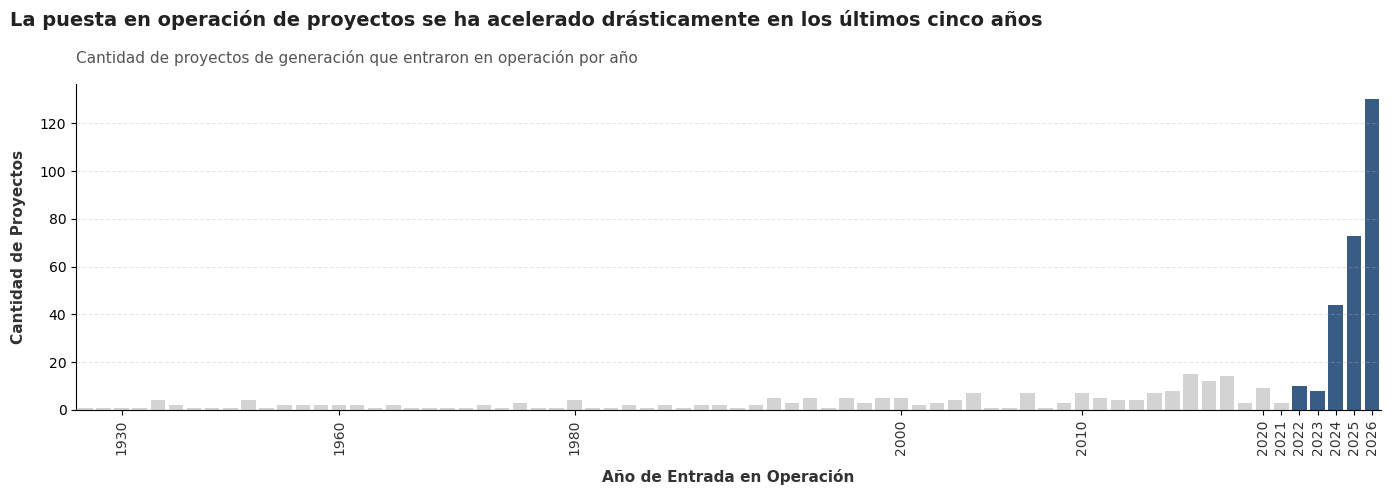

In [113]:
#  Agrupar los datos por año para contar la cantidad de proyectos
df_proyectos_anio = (
    gdf_proyectos.groupby(gdf_proyectos['fecha_operacion'].dt.year)['fecha_operacion']
    .count()
    .reset_index(name='cantidad_proyectos')
)

plt.figure(figsize=(14, 5))

# Definir indicador booleano para los últimos años (2022 en adelante)
df_proyectos_anio['is_recent'] = df_proyectos_anio['fecha_operacion'] >= 2022

# Usar sns.barplot
ax = sns.barplot(
    data=df_proyectos_anio,
    x='fecha_operacion',
    y='cantidad_proyectos',
    hue='is_recent',
    palette={True: '#2b5c8f', False: '#d3d3d3'}
)

# Remover leyenda
if ax.legend_:
    ax.legend_.remove()

# Título principal de acción y subtítulo explicativo
plt.suptitle(
    "La puesta en operación de proyectos se ha acelerado drásticamente en los últimos cinco años", 
    x=0.01, y=0.98, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Cantidad de proyectos de generación que entraron en operación por año", 
    loc='left', fontsize=11, color='#555555', pad=15
)

# Filtrar marcas en el eje X para evitar saturación (mostrar cada 10 años y los recientes)
ticks_to_show = [i for i, yr in enumerate(df_proyectos_anio['fecha_operacion']) if yr % 10 == 0 or yr >= 2020]
labels_to_show = [int(yr) for i, yr in enumerate(df_proyectos_anio['fecha_operacion']) if yr % 10 == 0 or yr >= 2020]

plt.xticks(ticks_to_show, labels_to_show, rotation=90, fontsize=10, color='#333333')
plt.xlabel('Año de Entrada en Operación', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Cantidad de Proyectos', fontsize=11, labelpad=10, fontweight='bold', color='#333333')

# Limpieza de bordes y rejilla
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

El análisis temporal revela un cambio estructural en la entrada en operación de proyectos de generación en Colombia. Históricamente (1950–2018), el Sistema Interconectado Nacional (SIN) registraba una incorporación modesta y centralizada, con promedios inferiores a 10 plantas anuales.

A partir del año 2020 se evidencia una aceleración exponencial en el número de registros, alcanzando un máximo histórico de 120 unidades en 2026. Este fenómeno responde principalmente a la proliferación de esquemas de Autogeneración a Pequeña Escala (AGPE) y Generación Distribuida (GD).

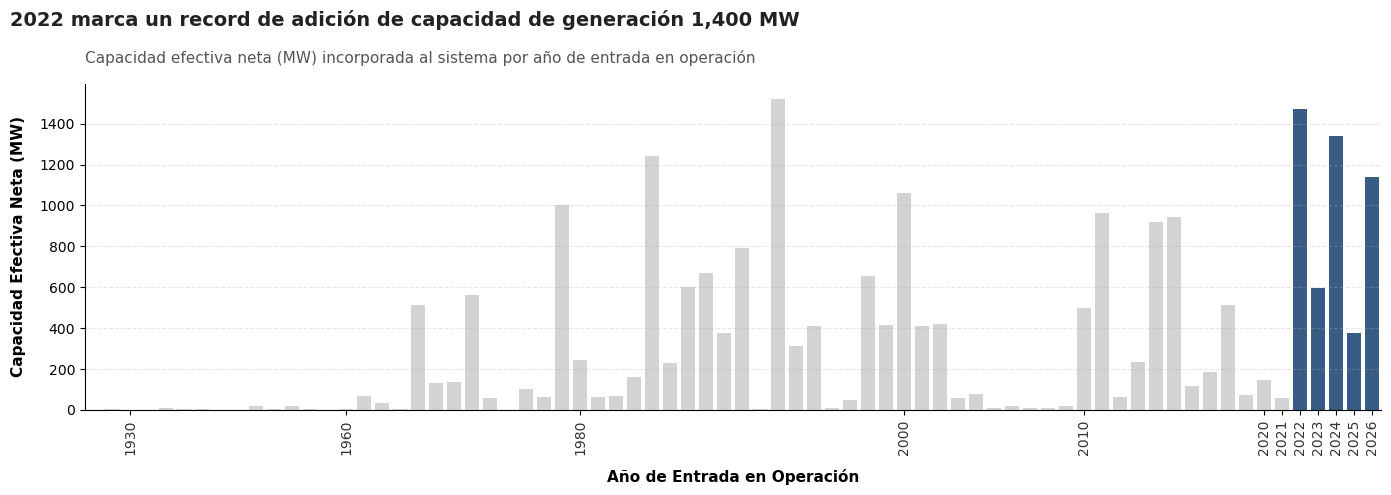

In [114]:
plt.figure(figsize=(14, 5))
df_capacidad_anio = (
    gdf_proyectos.groupby('anio_fpo')['capacidad_efectiva_neta_mw']
    .sum()
    .reset_index()
)

df_capacidad_anio['is_recent'] = df_proyectos_anio['fecha_operacion'] >= 2022

#  Usar sns.barplot
ax = sns.barplot(
    data=df_capacidad_anio,
    x='anio_fpo',
    y='capacidad_efectiva_neta_mw',
    hue='is_recent',
    palette={True: '#2b5c8f', False: '#d3d3d3'}
)

# Remover leyenda
if ax.legend_:
    ax.legend_.remove()

#  Título principal de acción y subtítulo explicativo
plt.suptitle(
    "2022 marca un record de adición de capacidad de generación 1,400 MW", 
    x=0.01, y=0.98, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad efectiva neta (MW) incorporada al sistema por año de entrada en operación", 
    loc='left', fontsize=11, color='#555555', pad=15
)

#  Filtrar marcas en el eje X para evitar saturación 
ticks_to_show = [i for i, yr in enumerate(df_capacidad_anio['anio_fpo']) if yr % 10 == 0 or yr >= 2020]
labels_to_show = [int(yr) for i, yr in enumerate(df_capacidad_anio['anio_fpo']) if yr % 10 == 0 or yr >= 2020]

plt.xticks(ticks_to_show, labels_to_show, rotation=90, fontsize=10, color='#333333')
plt.xlabel('Año de Entrada en Operación', fontsize=11, labelpad=10, fontweight='bold')
plt.ylabel('Capacidad Efectiva Neta (MW)', fontsize=11, labelpad=10, fontweight='bold')

# Limpieza de bordes y rejilla
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Al evaluar el volumen de potencia adicionado (MW), el comportamiento del sistema exhibe una dinámica discreta y relativamente continua en cantidad de megavatios, fuertemente condicionada por la entrada en operación comercial de megaproyectos de infraestructura (visibles en los picos de 1993, 2014–2015 y el máximo histórico de 2023).

Al contrastar esta gráfica con el número de proyectos registrados en el mismo período, se confirma un desacople entre ambas variables: si bien entre 2020 y 2026 el número de entradas al sistema creció de forma exponencial, la adición de capacidad en MW creció a un ritmo moderado y fraccionado.

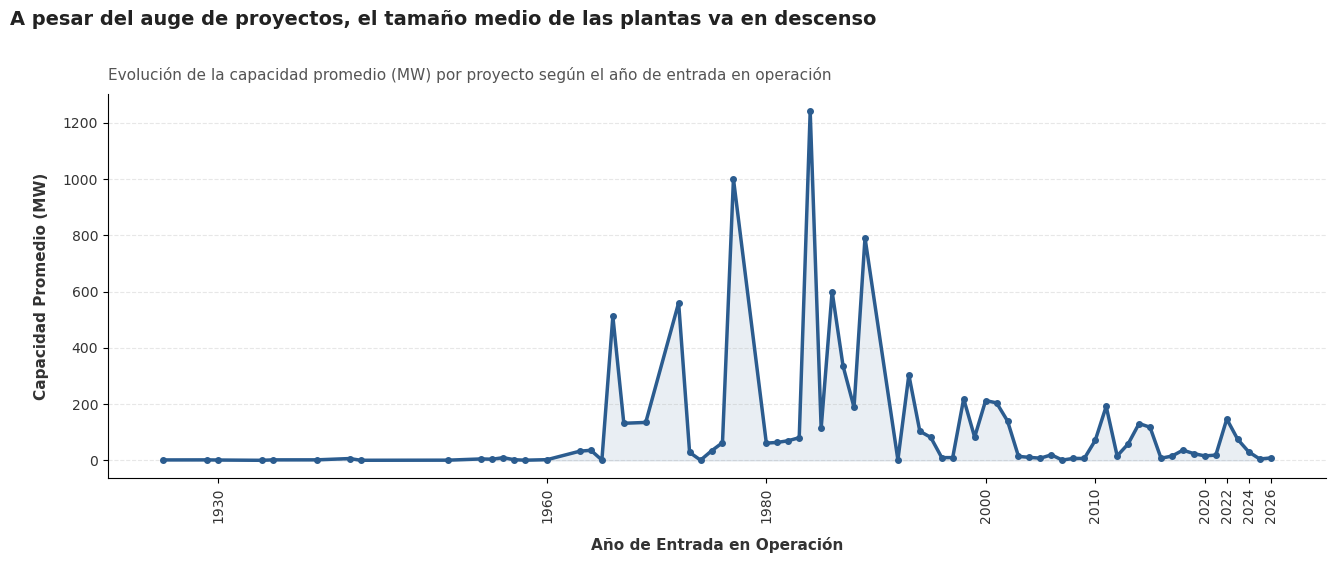

In [115]:
# 1. Agrupar para obtener la capacidad promedio por año de entrada en operación
df_promedio = (
    gdf_proyectos.groupby('anio_fpo')['capacidad_efectiva_neta_mw']
    .mean()
    .reset_index()
    .rename(columns={'capacidad_efectiva_neta_mw': 'capacidad_promedio'})
)

# 2. Crear figura con proporciones equilibradas
fig, ax = plt.subplots(figsize=(14, 6))
fig.subplots_adjust(top=0.82, bottom=0.18, left=0.08, right=0.95)

# 3. Graficar línea de evolución histórica
ax.plot(
    df_promedio['anio_fpo'], 
    df_promedio['capacidad_promedio'], 
    color='#2b5c8f', 
    linewidth=2.5, 
    marker='o', 
    markersize=4,
    markerfacecolor='#2b5c8f'
)

# Rellenar bajo la curva para acentuar el volumen histórico
ax.fill_between(
    df_promedio['anio_fpo'], 
    df_promedio['capacidad_promedio'], 
    color='#2b5c8f', 
    alpha=0.1
)

# 4. Título principal de acción y subtítulo limpios
plt.suptitle(
    "A pesar del auge de proyectos, el tamaño medio de las plantas va en descenso", 
    x=0.01, y=0.96, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Evolución de la capacidad promedio (MW) por proyecto según el año de entrada en operación", 
    loc='left', fontsize=11, color='#555555', pad=10
)

# 5. Filtrar ticks del eje X de forma limpia (décadas en histórico y años pares en periodo reciente)
anios_totales = sorted(df_promedio['anio_fpo'].unique())
ticks_destacados = [yr for yr in anios_totales if (yr % 10 == 0) or (yr >= 2020 and yr % 2 == 0)]

plt.xticks(ticks_destacados, [str(int(yr)) for yr in ticks_destacados], rotation=90, fontsize=10, color='#333333')
plt.yticks(fontsize=10, color='#333333')

plt.xlabel('Año de Entrada en Operación', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Capacidad Promedio (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')

# 6. Despine y cuadrícula sutil
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

**Evolución de la Capacidad Promedio por Proyecto (MW/Planta)**

El análisis de capacidad promedio por planta confirma el cambio estructural en el modelo de expansión del sistema colombiano. Durante los períodos de mayor desarrollo de grandes infraestructuras hídricas y térmicas (especialmente entre 1975 y 1995), el tamaño promedio por proyecto en su año de entrada en operación oscilaba habitualmente entre los 300 MW y más de 1,200 MW por planta, centrando esfuerzos en pocos proyectos de alto impacto.

En contraste, a partir de la década de 2010 y con mayor énfasis en el quinquenio 2021–2026, la capacidad promedio por unidad adicionada se comprime significativamente a valores inferiores a 20 MW por proyecto.

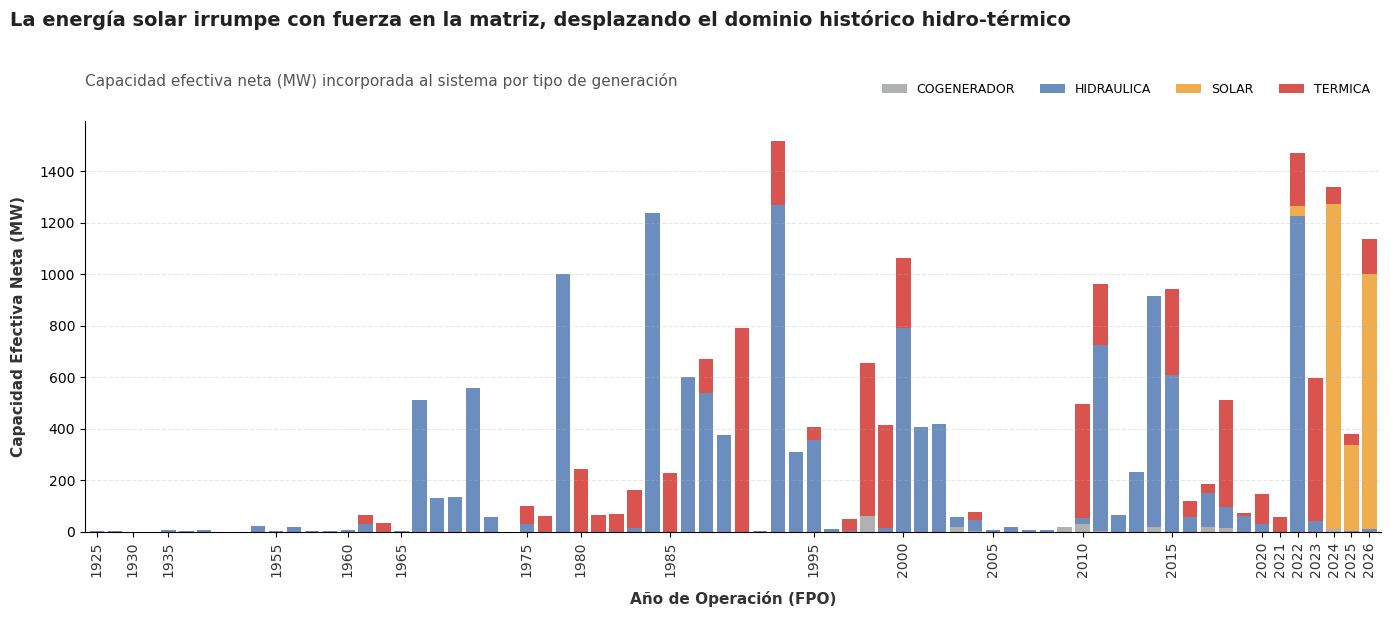

In [116]:
# 1. Pivotar datos
df_pivot = (
    gdf_proyectos.groupby(['anio_fpo', 'tipo_generacion'])['capacidad_efectiva_neta_mw']
    .sum()
    .unstack(fill_value=0)
)

# 2. Definir paleta de colores semántica y limpia
colores_tecnologia = {
    'HIDRAULICA': '#6c8ebf',   # Azul histórico atenuado
    'TERMICA': '#d9534f',      # Rojo histórico atenuado
    'SOLAR': '#f0ad4e',        # Naranja/Amarillo brillante 
    'EOLICA': '#5cb85c',       # Verde suave
    'COGENERADOR': '#b0b1b2',  # Gris neutro
    'BIOMASA': '#8a6d3b'       # Café suave
}

colors_list = [colores_tecnologia.get(col, '#d3d3d3') for col in df_pivot.columns]

# 3. Crear figura
fig, ax = plt.subplots(figsize=(14, 6))

# Graficar barras apiladas
df_pivot.plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    color=colors_list, 
    width=0.8,
    linewidth=0
)

# 4. Título principal de acción y subtítulo con separación adecuada (y ajustada)
plt.suptitle(
    "La energía solar irrumpe con fuerza en la matriz, desplazando el dominio histórico hidro-térmico", 
    x=0.01, y=1.02, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad efectiva neta (MW) incorporada al sistema por tipo de generación", 
    loc='left', fontsize=11, color='#555555', pad=25
)

# 5. Leyenda limpia posicionada a la derecha de forma horizontal superior
ax.legend(
    title='', 
    bbox_to_anchor=(1.0, 1.12), 
    loc='upper right', 
    ncol=len(df_pivot.columns), 
    frameon=False, 
    fontsize=9
)

# 6. Filtrar marcas en el eje X para evitar que los años recientes se amontonen
anos_lista = df_pivot.index.tolist()
ticks_to_show = [i for i, yr in enumerate(anos_lista) if yr % 5 == 0 or yr >= 2020]
labels_to_show = [int(yr) for i, yr in enumerate(anos_lista) if yr % 5 == 0 or yr >= 2020]

plt.xticks(ticks_to_show, labels_to_show, rotation=90, fontsize=10, color='#333333')
plt.xlabel('Año de Operación (FPO)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Capacidad Efectiva Neta (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')

# 7. Despine y Grid suave
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Históricamente, la expansión del SIN estuvo cimentada en dos pilares: centrales hidráulicas (color azul) para cubrir la demanda base y plantas térmicas (color rojo) para aportar energía en firme y respaldo hídrico en épocas de sequía.  A partir del período 2022–2024 se evidencia un punto de inflexión: la tecnología solar fotovoltaica (color naranja), pasa de una participación marginal a dominar ampliamente el volumen de capacidad adicional instalada entre 2024 y 2026. Sin embargo, es importante notar, que algunas 

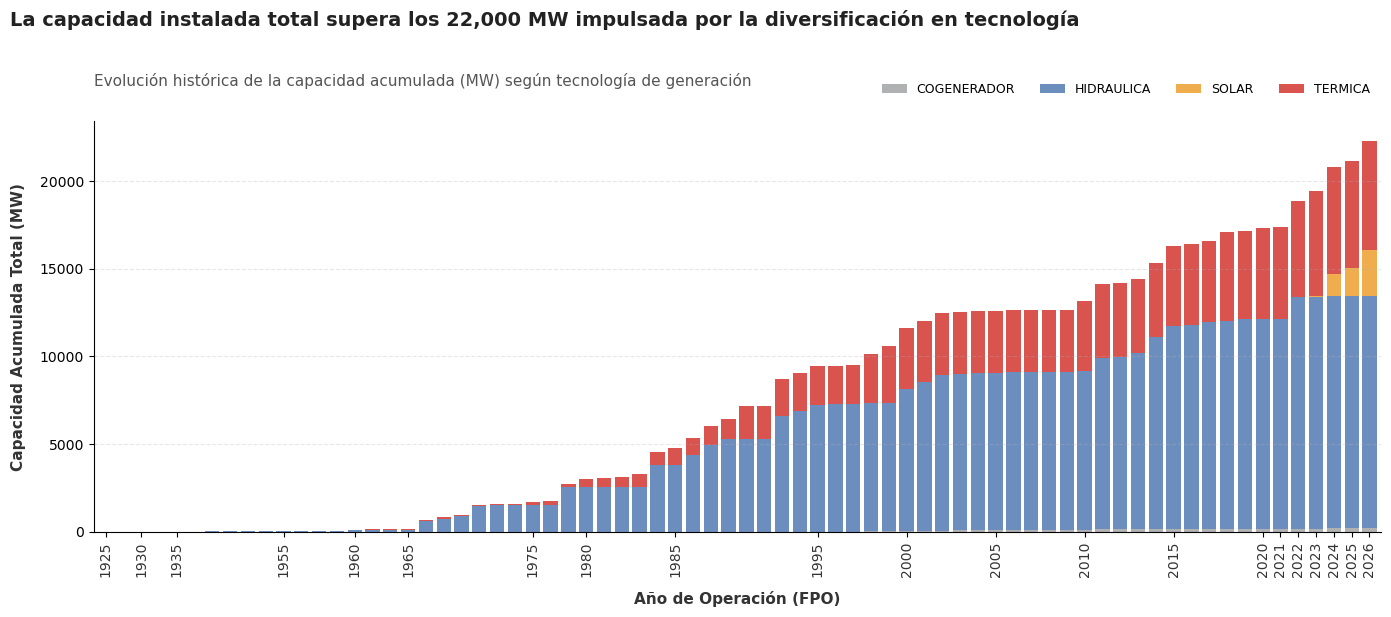

In [117]:
# 1. Pivotar y calcular la suma acumulada a lo largo de los años

df_acumulado = df_pivot.cumsum()

# 2. Diccionario de colores semántico y limpio
colores_tecnologia = {
    'HIDRAULICA': '#6c8ebf',   # Azul histórico atenuado
    'TERMICA': '#d9534f',      # Rojo histórico atenuado
    'SOLAR': '#f0ad4e',        # Naranja/Amarillo brillante
    'EOLICA': '#5cb85c',       # Verde suave
    'COGENERADOR': '#b0b1b2',  # Gris neutro
    'BIOMASA': '#8a6d3b'       # Café suave
}

colors_list = [colores_tecnologia.get(col, '#d3d3d3') for col in df_acumulado.columns]

# 3. Crear figura
fig, ax = plt.subplots(figsize=(14, 6))

# Graficar barras apiladas acumuladas (sin bordes pesados)
df_acumulado.plot(
    kind='bar', 
    stacked=True, 
    ax=ax, 
    color=colors_list, 
    width=0.8,
    linewidth=0
)

# 4. Título principal de acción y subtítulo (en español)
plt.suptitle(
    "La capacidad instalada total supera los 22,000 MW impulsada por la diversificación en tecnología", 
    x=0.01, y=1.02, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Evolución histórica de la capacidad acumulada (MW) según tecnología de generación", 
    loc='left', fontsize=11, color='#555555', pad=25
)

# 5. Leyenda limpia horizontal superior derecha
ax.legend(
    title='', 
    bbox_to_anchor=(1.0, 1.12), 
    loc='upper right', 
    ncol=len(df_acumulado.columns), 
    frameon=False, 
    fontsize=9
)

# 6. Filtrar marcas en el eje X para evitar saturación y mantener visibilidad clara
anos_lista = df_acumulado.index.tolist()
ticks_to_show = [i for i, yr in enumerate(anos_lista) if yr % 5 == 0 or yr >= 2020]
labels_to_show = [int(yr) for i, yr in enumerate(anos_lista) if yr % 5 == 0 or yr >= 2020]

plt.xticks(ticks_to_show, labels_to_show, rotation=90, fontsize=10, color='#333333')
plt.xlabel('Año de Operación (FPO)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Capacidad Acumulada Total (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')

# 7. Despine y rejilla suave
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Una vez analizadas las adiciones anuales marginales por tecnología, resulta fundamental evaluar el impacto acumulado de esta penetración solar sobre la estructura consolidada del parque generador nacional, en donde a pesar de la predominancia de las fuentes tradicionales, el componente solar se posiciona cómo la tecnología de mayor crecimiento.

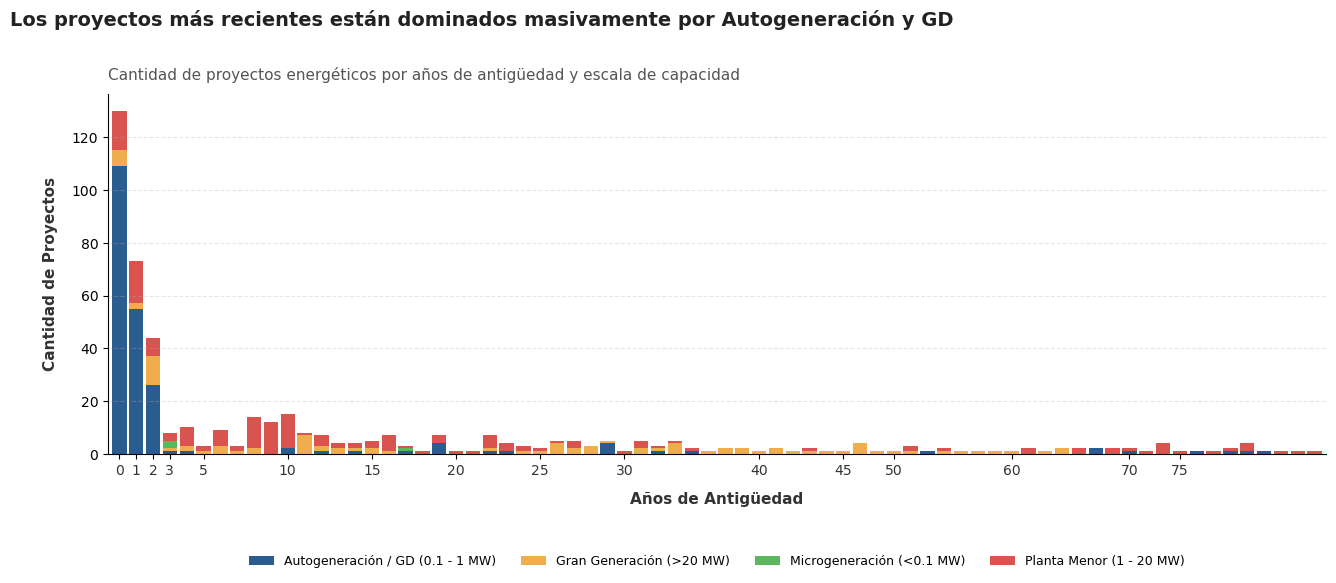

In [118]:
# 1. Agrupar datos por antigüedad y rango de capacidad
df_antiguedad = (
    gdf_proyectos.groupby(['antiguedad_anios', 'rango_capacidad'])
    .size()
    .unstack(fill_value=0)
)

# 2. Definir paleta de colores semántica y limpia
colores_rango = {
    'Autogeneración / GD (0.1 - 1 MW)': '#2b5c8f',  # Azul fuerte (Focal)
    'Planta Menor (1 - 20 MW)': '#d9534f',          # Rojo/Rosado
    'Gran Generación (>20 MW)': '#f0ad4e',          # Naranja
    'Microgeneración (<0.1 MW)': '#5cb85c'          # Verde
}

colors_list = [colores_rango.get(col, '#d3d3d3') for col in df_antiguedad.columns]

# 3. Crear figura con espacio inferior reservado para la leyenda
fig, ax = plt.subplots(figsize=(14, 6))
fig.subplots_adjust(top=0.82, bottom=0.22, left=0.08, right=0.95)  # Márgenes amplios y equilibrados

# Graficar barras apiladas aprovechando todo el ancho
df_antiguedad.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors_list,
    width=0.85,
    linewidth=0,
    legend=False
)

# 4. Título principal de acción y subtítulo limpios arriba
plt.suptitle(
    "Los proyectos más recientes están dominados masivamente por Autogeneración y GD", 
    x=0.01, y=0.96, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Cantidad de proyectos energéticos por años de antigüedad y escala de capacidad", 
    loc='left', fontsize=11, color='#555555', pad=10
)

# 5. Leyenda horizontal limpia en la PARTE INFERIOR (fuera del área de barras)
ax.legend(
    title='', 
    bbox_to_anchor=(0.5, -0.25),  # Ubicada debajo del eje X
    loc='upper center', 
    ncol=4,  # Todos los elementos en una sola fila horizontal
    frameon=False, 
    fontsize=9
)

# 6. Filtrar marcas en el eje X
anios_lista = df_antiguedad.index.tolist()
ticks_to_show = [i for i, yr in enumerate(anios_lista) if yr % 5 == 0 or yr <= 3]
labels_to_show = [int(yr) for i, yr in enumerate(anios_lista) if yr % 5 == 0 or yr <= 3]

plt.xticks(ticks_to_show, labels_to_show, rotation=0, fontsize=10, color='#333333')
plt.xlabel('Años de Antigüedad', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Cantidad de Proyectos', fontsize=11, labelpad=10, fontweight='bold', color='#333333')

# 7. Despine y cuadrícula sutil
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

La antiguedad del parque generador, muestra la proliferación de plantas en los últimos 3 años, y el fuerte impulso de la autogeneración en el sistema colombiano.

### 6.2 Analizemos cómo varía el sistema de generación a nivel regional.

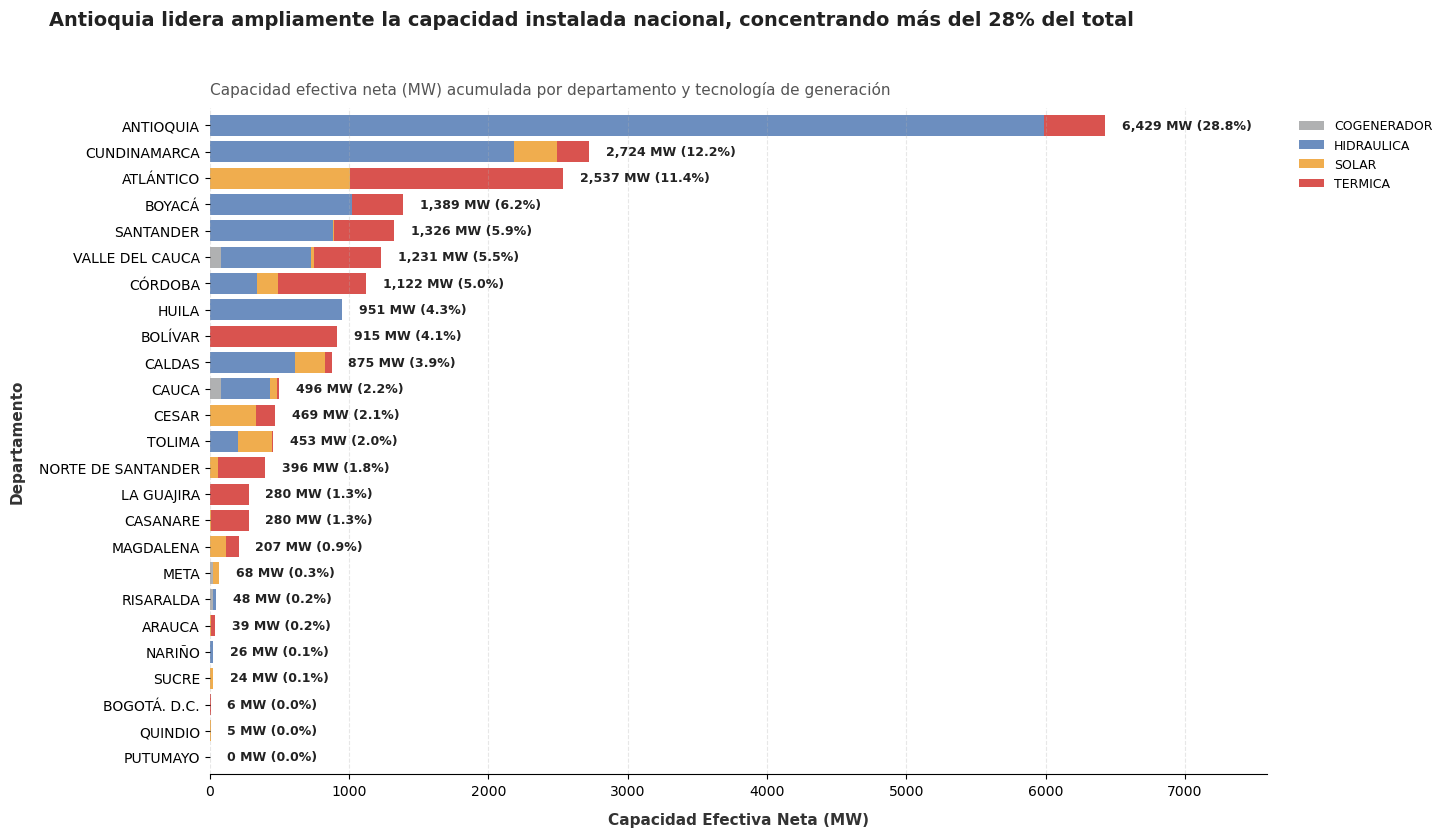

In [119]:
# 1. Agrupar por departamento y tipo de generación
df_tipo = (
    gdf_proyectos.groupby(['departamento_oficial', 'tipo_generacion'])['capacidad_efectiva_neta_mw']
    .sum()
    .unstack(fill_value=0)
)

# 2. Ordenar departamentos por capacidad total descendente
df_tipo['TOTAL_Mw'] = df_tipo.sum(axis=1)
df_tipo = df_tipo.sort_values(by='TOTAL_Mw', ascending=False)

totales = df_tipo['TOTAL_Mw']
df_plot = df_tipo.drop(columns=['TOTAL_Mw'])

# Mapeo de colores semántico y limpio
colores_tipo = {
    'COGENERADOR': '#b0b1b2',  # Gris neutro
    'EOLICA': '#5cb85c',       # Verde suave
    'HIDRAULICA': '#6c8ebf',   # Azul histórico atenuado
    'SOLAR': '#f0ad4e',        # Naranja/Amarillo brillante (Focal)
    'TERMICA': '#d9534f'       # Rojo histórico atenuado
}

colors_presentes = [colores_tipo.get(col, '#d3d3d3') for col in df_plot.columns]

total_nacional = totales.sum()
pct_global = (totales / total_nacional) * 100

# 3. Crear figura con altura balanceada y espacio superior controlado
fig, ax = plt.subplots(figsize=(14, 9))
fig.subplots_adjust(top=0.85, right=0.88)  # Espacio superior y derecho equilibrados

# Graficar barras horizontales apiladas
df_plot.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    color=colors_presentes, 
    width=0.8,
    linewidth=0
)

ax.invert_yaxis()

# 4. Etiquetas de total y porcentaje al final de cada barra
for i, (dept, total_mw) in enumerate(totales.items()):
    pct = pct_global[dept]
    ax.text(
        total_mw + 120, i, 
        f'{total_mw:,.0f} MW ({pct:.1f}%)', 
        va='center', ha='left', 
        fontsize=9, fontweight='bold', color='#222222'
    )

# 5. Título principal de acción y subtítulo con espaciado natural
plt.suptitle(
    "Antioquia lidera ampliamente la capacidad instalada nacional, concentrando más del 28% del total", 
    x=0.01, y=0.96, ha='left', fontsize=14, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad efectiva neta (MW) acumulada por departamento y tecnología de generación", 
    loc='left', fontsize=11, color='#555555', pad=10
)

# 6. Leyenda alineada limpiamente a la derecha en la parte superior del gráfico
ax.legend(
    title='', 
    bbox_to_anchor=(1.02, 1.0), 
    loc='upper left', 
    ncol=1, 
    frameon=False, 
    fontsize=9
)

# 7. Formato de ejes y estilo visual
plt.xlabel('Capacidad Efectiva Neta (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Departamento', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.xlim(0, totales.max() * 1.18)

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

Al analizar la capacidad instalada en OPERACIÓN comercial, Antioquia, Cundinamarca y Atlántico concentran más del 50% de la capacidad total del SIN. Al excluir el 1.13 GW de proyectos solares en pruebas, el peso porcentual de la generación hidroeléctrica y térmica tradicional aumenta dentro de la matriz regulada.

La composición por tipo de generación muestra dos dinámicas:

• Polos del Interior: Antioquia y Cundinamarca lideran con oferta hídrica y térmica firme para la suficiencia del sistema, este último incluso diversificando a Solar.

• Nodos de Transición: Atlántico, Córdoba, Tolima y Cesar muestran el avance solar del país

Resulta clave profundizar en la dinámica de estos departamentos para el periodo 2022–2026, con el fin de dimensionar el ritmo de aceleración y descentralización del parque generador en los últimos años.

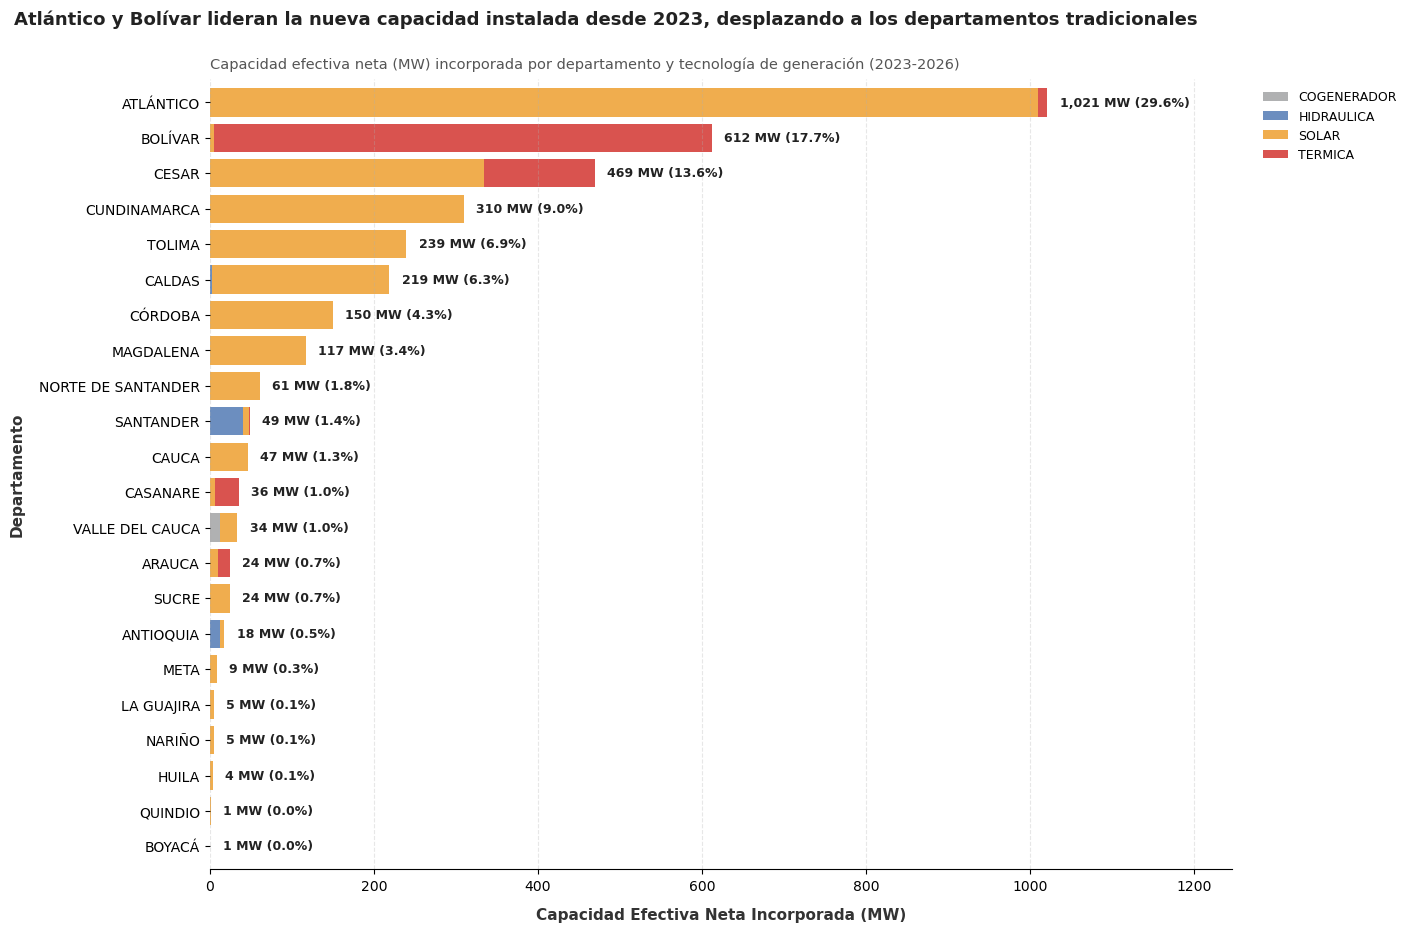

In [120]:
# 1. Agrupar por departamento y tipo de generación filtrando desde 2023
df_reciente = gdf_proyectos[gdf_proyectos['anio_fpo'] > 2022]
df_tipo = (
    df_reciente.groupby(['departamento_oficial', 'tipo_generacion'])['capacidad_efectiva_neta_mw']
    .sum()
    .unstack(fill_value=0)
)

# 2. Ordenar departamentos por capacidad total descendente
df_tipo['TOTAL_Mw'] = df_tipo.sum(axis=1)
df_tipo_reciente = df_tipo.sort_values(by='TOTAL_Mw', ascending=False)

totales = df_tipo_reciente['TOTAL_Mw']
df_plot = df_tipo_reciente.drop(columns=['TOTAL_Mw'])

# Mapeo de colores semántico y limpio
colores_tipo = {
    'COGENERADOR': '#b0b1b2',  # Gris neutro
    'EOLICA': '#5cb85c',       # Verde suave
    'HIDRAULICA': '#6c8ebf',   # Azul histórico atenuado
    'SOLAR': '#f0ad4e',        # Naranja/Amarillo brillante (Focal)
    'TERMICA': '#d9534f'       # Rojo histórico atenuado
}

colors_presentes = [colores_tipo.get(col, '#d3d3d3') for col in df_plot.columns]

total_nacional = totales.sum()
pct_global = (totales / total_nacional) * 100

# 3. Crear figura con un margen superior optimizado (top=0.90 elimina el espacio excesivo)
fig, ax = plt.subplots(figsize=(14, 10))
fig.subplots_adjust(top=0.90, right=0.88, left=0.15)

# Graficar barras horizontales apiladas
df_plot.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    color=colors_presentes, 
    width=0.8,
    linewidth=0,
    legend=False
)

ax.invert_yaxis()  # Mantener el departamento de mayor capacidad arriba

# 4. Etiquetas de total y porcentaje al final de cada barra
for i, (dept, total_mw) in enumerate(totales.items()):
    pct = pct_global[dept]
    ax.text(
        total_mw + 15, i, 
        f'{total_mw:,.0f} MW ({pct:.1f}%)', 
        va='center', ha='left', 
        fontsize=9, fontweight='bold', color='#222222'
    )

# 5. Título principal de acción y subtítulo compactados y armónicos
plt.suptitle(
    "Atlántico y Bolívar lideran la nueva capacidad instalada desde 2023, desplazando a los departamentos tradicionales", 
    x=0.01, y=0.97, ha='left', fontsize=13, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad efectiva neta (MW) incorporada por departamento y tecnología de generación (2023-2026)", 
    loc='left', fontsize=10.5, color='#555555', pad=8
)

# 6. Leyenda limpia reubicada a la derecha del gráfico
ax.legend(
    title='', 
    bbox_to_anchor=(1.02, 1.0), 
    loc='upper left', 
    ncol=1, 
    frameon=False, 
    fontsize=9
)

# 7. Formato de ejes y estilo visual
plt.xlabel('Capacidad Efectiva Neta Incorporada (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Departamento', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.xlim(0, totales.max() * 1.22)

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

El análisis del periodo 2023–2026 confirma la transformación hacia la tecnología solar fotovoltaica, la cual impulsa casi la totalidad de la nueva capacidad en construcción o entrada en operación. 

Esta dinámica desplaza los centros de crecimiento hacia el departamento del Atlántico (1,021 MW, representando el 29.6% del total del cuatrienio), seguido de Bolívar, Cesar, Cundinamarca  y Tolima. Mientras que Bolívar combina la expansión solar con capacidad térmica de respaldo, departamentos como Cundinamarca y Córdoba complementan su infraestructura tradicional mediante la incorporación masiva de parques fotovoltaicos. 

En contraste, las regiones de generación hídrica histórica presentan adiciones marginales en este periodo, evidenciando el cambio de foco de las inversiones hacia las Fuentes No Convencionales de Energía Renovable (FNCER) en el Caribe y el Valle del Magdalena. 


Consideraciones adicionales: 

* Este cambio de foco de inversiones debe verificarse en las nuevas convocatorias de proyectos futuros, corroborando su permanencia en el tiempo.

* Resulta de interés verificar cómo el ingreso de está capacidad adicional en focos de generación no tradicionales está impactando el precio de la energía a clientes en estos departamentos.

### 6.3 Analizemos los principales agentes generadores:

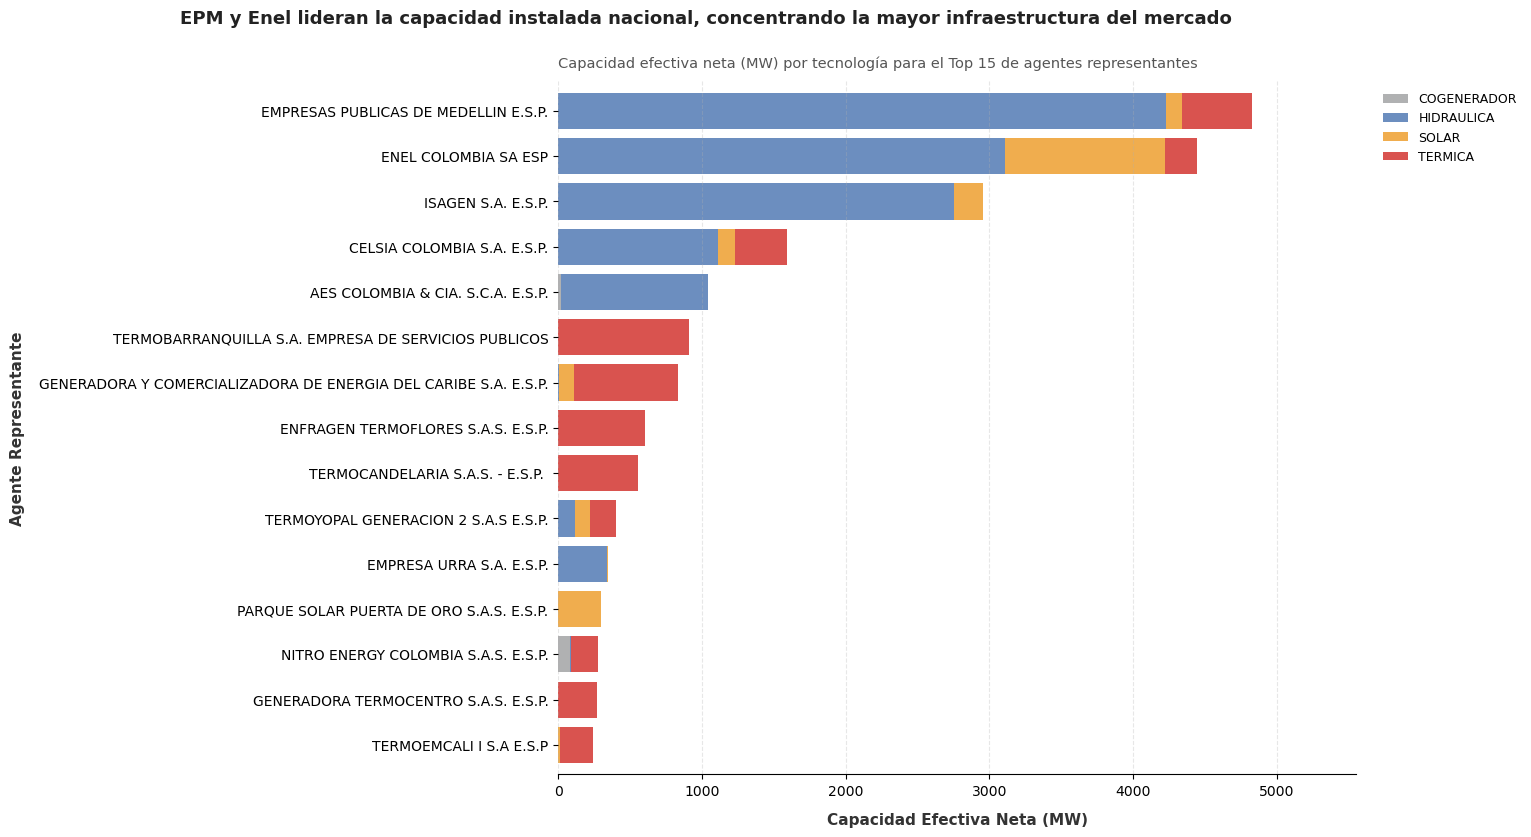

In [121]:
# 1. Agrupar por agente representante y tipo de generación (Top 15)
df_agentes = (
    gdf_proyectos.groupby('agente_representante')
    .agg(
        mw_totales=('capacidad_efectiva_neta_mw', 'sum'),
        num_proyectos=('capacidad_efectiva_neta_mw', 'count'),
        tecnologia_principal=('tipo_generacion', lambda x: x.mode()[0] if not x.empty else 'NO')
    )
    .reset_index()
    .sort_values(by='mw_totales', ascending=False)
)

top_agents_list = df_agentes.head(15)['agente_representante'].tolist()

df_agents_tech = (
    gdf_proyectos[gdf_proyectos['agente_representante'].isin(top_agents_list)]
    .groupby(['agente_representante', 'tipo_generacion'])['capacidad_efectiva_neta_mw']
    .sum()
    .unstack(fill_value=0)
)

# Reordenar según el total de MW de forma ascendente para barh
df_agents_tech['TOTAL'] = df_agents_tech.sum(axis=1)
df_agents_tech = df_agents_tech.sort_values(by='TOTAL', ascending=True).drop(columns=['TOTAL'])

# 2. Mapeo de colores semántico y limpio
colores_tipo = {
    'COGENERADOR': '#b0b1b2',  # Gris neutro
    'EOLICA': '#5cb85c',       # Verde suave
    'HIDRAULICA': '#6c8ebf',   # Azul histórico atenuado
    'SOLAR': '#f0ad4e',        # Naranja/Amarillo brillante (Focal)
    'TERMICA': '#d9534f'       # Rojo histórico atenuado
}

colors_presentes = [colores_tipo.get(col, '#d3d3d3') for col in df_agents_tech.columns]

# 3. Crear figura con márgenes optimizados para los nombres de los agentes
fig, ax = plt.subplots(figsize=(14, 9))
fig.subplots_adjust(top=0.88, right=0.85, left=0.28)  # Margen izquierdo amplio para textos largos

# Graficar barras horizontales apiladas sin bordes pesados y apagando leyenda automática
df_agents_tech.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    color=colors_presentes,
    width=0.8,
    linewidth=0,
    legend=False
)

# 4. Título principal de acción y subtítulo limpios
plt.suptitle(
    "EPM y Enel lideran la capacidad instalada nacional, concentrando la mayor infraestructura del mercado", 
    x=0.01, y=0.96, ha='left', fontsize=13, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad efectiva neta (MW) por tecnología para el Top 15 de agentes representantes", 
    loc='left', fontsize=10.5, color='#555555', pad=10
)

# 5. Leyenda limpia reubicada a la derecha del gráfico
ax.legend(
    title='', 
    bbox_to_anchor=(1.02, 1.0), 
    loc='upper left', 
    ncol=1, 
    frameon=False, 
    fontsize=9
)

# 6. Formato de ejes y estilo visual
plt.xlabel('Capacidad Efectiva Neta (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Agente Representante', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.xlim(0, df_agents_tech.sum(axis=1).max() * 1.15)

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

Al analizar la capacidad instalada por agente del mercado, se evidencian marcadas asimetrías en la adopción y velocidad de despliegue de proyectos solares fotovoltaicos entre los principales actores del Sistema Interconectado Nacional (SIN).

Enel Colombia y Celsia se consolidan como los líderes de la transición energética en el segmento de grandes generadores, integrando bloques significativos de energía solar a sus portafolios hidro-térmicos. En contraste, agentes de gran envergadura como EPM e Isagen mantienen una matriz predominantemente hidráulica, mostrando una incorporación solar más conservadora o rezagada.

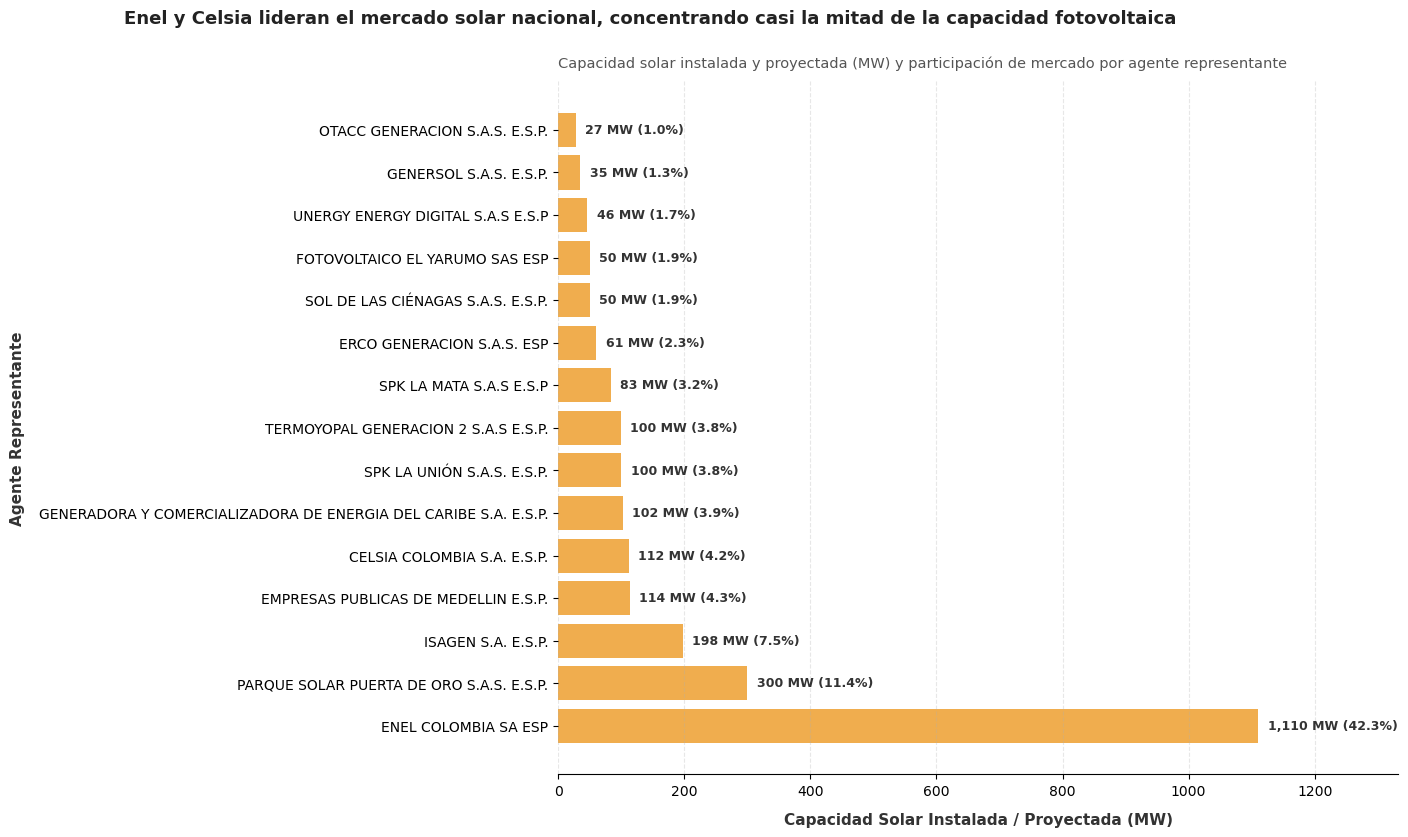

In [122]:
# 1. Filtrar exclusivamente tecnología SOLAR
df_solar = gdf_proyectos[gdf_proyectos['tipo_generacion'] == 'SOLAR'].copy()

# 2. Agrupar por agente representante
matriz_solar = (
    df_solar.groupby('agente_representante')
    .agg(
        mw_solar=('capacidad_efectiva_neta_mw', 'sum'),
        num_proyectos=('capacidad_efectiva_neta_mw', 'count'),
        municipios_presencia=('municipio_oficial', lambda x: x.nunique())
    )
    .reset_index()
    .sort_values(by='mw_solar', ascending=False)
)

# 3. Calcular participaciones de mercado
total_mw_solar = df_solar['capacidad_efectiva_neta_mw'].sum()
matriz_solar['part_mercado_pct'] = (matriz_solar['mw_solar'] / total_mw_solar) * 100
matriz_solar['part_acumulada_pct'] = matriz_solar['part_mercado_pct'].cumsum()

# 4. Seleccionar el Top 15 y ordenar de forma ascendente para barh
top15_solar = matriz_solar.head(15).sort_values(by='mw_solar', ascending=True).reset_index(drop=True)

# 5. Crear figura con margen izquierdo amplio para los nombres de las empresas
fig, ax1 = plt.subplots(figsize=(14, 9))
fig.subplots_adjust(top=0.88, right=0.92, left=0.32)  # Margen izquierdo optimizado

# Barras de capacidad solar (color solar focal, sin bordes pesados)
bars = ax1.barh(
    top15_solar['agente_representante'],
    top15_solar['mw_solar'],
    color='#f0ad4e',  # Naranja solar brillante
    linewidth=0
)

ax1.invert_yaxis()  # El mayor agente solar arriba

# 6. Título principal de acción y subtítulo
plt.suptitle(
    "Enel y Celsia lideran el mercado solar nacional, concentrando casi la mitad de la capacidad fotovoltaica", 
    x=0.01, y=0.96, ha='left', fontsize=13, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad solar instalada y proyectada (MW) y participación de mercado por agente representante", 
    loc='left', fontsize=10.5, color='#555555', pad=10
)

# 7. Etiquetas de datos al final de las barras
for bar, pct in zip(bars, top15_solar['part_mercado_pct']):
    width = bar.get_width()
    ax1.text(
        width + 15, 
        bar.get_y() + bar.get_height() / 2, 
        f'{width:,.0f} MW ({pct:.1f}%)', 
        va='center', 
        ha='left', 
        fontsize=9, 
        fontweight='bold', 
        color='#333333'
    )

# 8. Formato de ejes y estilo visual
plt.xlabel('Capacidad Solar Instalada / Proyectada (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Agente Representante', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
ax1.set_xlim(0, top15_solar['mw_solar'].max() * 1.20)

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

El análisis de la matriz de proyectos Solares, los de mayor crecimiento en Colombia, muestra un cambio estructural en el mercado, donde los agentes tradicionales, empiezan a competir con generadores de menor escala.

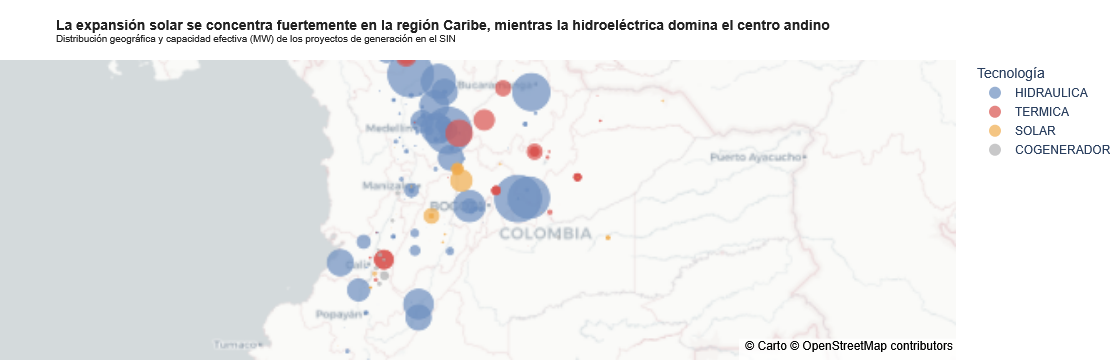

In [123]:
import plotly.express as px

# 1. Preparar datos para el mapa
df_mapa = gdf_proyectos.copy()

# 2. Crear mapa de burbujas interactivo con Plotly Express
fig = px.scatter_mapbox(
    df_mapa,
    lat='latitud',
    lon='longitud',
    size='capacidad_efectiva_neta_mw',
    color='tipo_generacion',
    hover_name='municipio_oficial',
    hover_data={
        'departamento_oficial': True,
        'agente_representante': True,
        'capacidad_efectiva_neta_mw': ':.1f',  # Formato numérico flotante a 1 decimal
        'latitud': False,
        'longitud': False,
    },
    labels={
        'capacidad_efectiva_neta_mw': 'Capacidad (MW)',
        'departamento_oficial': 'Departamento',
        'agente_representante': 'Agente',
        'tipo_generacion': 'Tecnología'
    },
    color_discrete_map={
        'SOLAR': '#f0ad4e',       # Naranja solar brillante (Focal)
        'TERMICA': '#d9534f',     # Rojo histórico atenuado
        'HIDRAULICA': '#6c8ebf',  # Azul histórico atenuado
        'COGENERADOR': '#b0b1b2', # Gris neutro
        'EOLICA': '#5cb85c'       # Verde suave
    },
    size_max=35,
    zoom=5.1,  # Zoom ligeramente más cercano para destacar el territorio nacional
    center={"lat": 4.5709, "lon": -74.2973},  # Centro geográfico de Colombia
    mapbox_style="carto-positron",
    title="<b>La expansión solar se concentra fuertemente en la región Caribe, mientras la hidroeléctrica domina el centro andino</b><br><sup>Distribución geográfica y capacidad efectiva (MW) de los proyectos de generación en el SIN</sup>"
)

# 3. Ajustes finos de diseño y layout
fig.update_layout(
    margin={"r": 0, "t": 60, "l": 0, "b": 0},
    legend_title_text='Tecnología',
    font=dict(family="Arial, sans-serif", size=12),
    title_font=dict(size=14, color='#222222'),
)

fig.show()

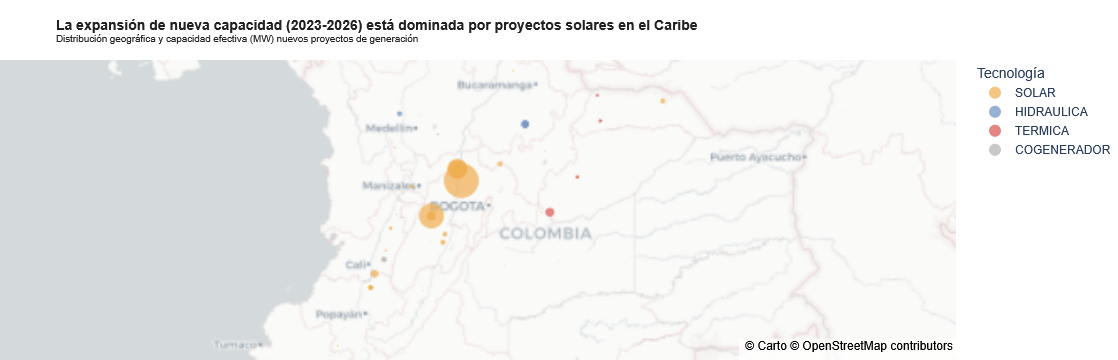

In [124]:
import plotly.express as px

# 1. Filtrar para el período 2023-2026
df_mapa = gdf_proyectos[gdf_proyectos['anio_fpo'] > 2022].copy()

# 2. Crear mapa de burbujas interactivo con Plotly Express
fig = px.scatter_mapbox(
    df_mapa,
    lat='latitud',
    lon='longitud',
    size='capacidad_efectiva_neta_mw',
    color='tipo_generacion',
    hover_name='municipio_oficial',
    hover_data={
        'departamento_oficial': True,
        'agente_representante': True,
        'capacidad_efectiva_neta_mw': ':.1f',  # Formato numérico flotante a 1 decimal
        'latitud': False,
        'longitud': False,
    },
    labels={
        'capacidad_efectiva_neta_mw': 'Capacidad (MW)',
        'departamento_oficial': 'Departamento',
        'agente_representante': 'Agente',
        'tipo_generacion': 'Tecnología'
    },
    color_discrete_map={
        'SOLAR': '#f0ad4e',       # Naranja solar brillante (Focal)
        'TERMICA': '#d9534f',     # Rojo histórico atenuado
        'HIDRAULICA': '#6c8ebf',  # Azul histórico atenuado
        'COGENERADOR': '#b0b1b2', # Gris neutro
        'EOLICA': '#5cb85c'       # Verde suave
    },
    size_max=35,
    zoom=5.1,  # Encuadre ajustado y centrado en el país
    center={"lat": 4.5709, "lon": -74.2973},  # Centro geográfico de Colombia
    mapbox_style="carto-positron",
    title="<b>La expansión de nueva capacidad (2023-2026) está dominada por proyectos solares en el Caribe</b><br><sup>Distribución geográfica y capacidad efectiva (MW) nuevos proyectos de generación</sup>"
)

# 3. Ajustes finos de diseño y layout
fig.update_layout(
    margin={"r": 0, "t": 60, "l": 0, "b": 0},
    legend_title_text='Tecnología',
    font=dict(family="Arial, sans-serif", size=12),
    title_font=dict(size=14, color='#222222'),
)

fig.show()

Fuentes: 
    
1. Informe: Generación Eléctrica en Colombia 2026: Concentración, Riesgos y Transición Energética https://www.superservicios.gov.co/sites/default/files/inline-files/Generacion-Electrica-en-Colombia-2026.pdf
2. Información Disponible Website XM tipos de generación: https://www.xm.com.co/generacion/tipos